# 🪙 Crypto Trading Bot – Walk-Forward ML Backtest (BTC + ETH)
**Data:** Yahoo Finance daily candles – BTC (Sep 2014 se) aur ETH (Nov 2017 se)

**Bot ka idea:** roz subah model bolta hai *"kal price upar jayegi ya neeche?"*. Upar jaye toh coin hold karo, warna cash mein raho.

**Is project mein:**
1. **EDA** – price, returns, volatility, drawdown, BTC-ETH correlation
2. **Features** – moving averages, RSI, volatility, momentum (sirf past data se, future nahi)
3. **ML** – Logistic Regression, Decision Tree, Random Forest (80/20 time-based split) + **Time-series cross-validation**
4. **Walk-forward bot** – model har 30 din mein naye data par dobara seekhta hai ("bot seekhta rahe")
5. **Backtest** – fees ke saath, aur **Buy & Hold**, **Moving Average** aur **DCA** se comparison
6. **Mini bucket** – BTC + ETH ke beech paisa baantna (baad mein top-5 coins tak badha sakte hain)

⚠️ Ye seekhne ka project hai, financial advice nahi. Backtest asli trading ka guarantee nahi hota.
Code easy hai: **pandas + numpy** zyada, metrics **sklearn.metrics** se (aur ek jagah formula haath se bhi check kiya), seaborn charts, chhote chhote cells, **koi lambda nahi**, loop sirf jahan zaroori ho.

In [23]:
import numpy as np                                                # numbers aur maths ke liye
import pandas as pd                                               # data table (DataFrame) ke liye
import matplotlib.pyplot as plt                                   # charts ka base library
import seaborn as sns                                             # sundar charts ke liye
import joblib, os                                                 # model save karne aur folder banane ke liye

from sklearn.model_selection import train_test_split, cross_val_score, TimeSeriesSplit  # split aur time-series cross-validation ke liye
from sklearn.linear_model import LogisticRegression               # Logistic Regression model
from sklearn.tree import DecisionTreeClassifier                   # Decision Tree model
from sklearn.ensemble import RandomForestClassifier               # Random Forest model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  # score nikalne ke liye
from sklearn.metrics import confusion_matrix, classification_report  # confusion matrix aur poori report ke liye

sns.set_theme(style="whitegrid", palette="deep")                  # seaborn ka look set karo
pd.set_option("display.width", 200)                               # table ki width badhao
os.makedirs("models", exist_ok=True)                              # models ke liye folder banao

# 💡 INSIGHT: Sirf standard libraries use hui: pandas, numpy, seaborn aur sklearn (models + metrics). Koi special trading library
#    nahi, taaki code easy aur samajhne layak rahe.

In [24]:
import yfinance as yf                                              # Yahoo Finance se data laane ka library

btc = yf.download("BTC-USD", start="2014-01-01", auto_adjust=False)  # BTC ka daily data
btc.columns = btc.columns.get_level_values(0)                      # column ke naam saaf karo
btc.columns.name = None                                            # extra naam hatao
btc.to_csv("BTC-USD.csv")                                          # CSV file save karo

eth = yf.download("ETH-USD", start="2014-01-01", auto_adjust=False)  # ETH ka daily data
eth.columns = eth.columns.get_level_values(0)                      # column ke naam saaf karo
eth.columns.name = None                                            # extra naam hatao
eth.to_csv("ETH-USD.csv")                                          # CSV file save karo

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## 2. Data load aur quick checks

In [25]:
btc = pd.read_csv("BTC-USD.csv", index_col="Date", parse_dates=True)   # BTC ki CSV padho, Date ko index banao
eth = pd.read_csv("ETH-USD.csv", index_col="Date", parse_dates=True)   # ETH ki CSV padho, Date ko index banao

In [26]:
btc.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')

In [27]:
eth.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')

In [28]:
btc = btc[["Open", "High", "Low", "Close", "Volume"]].sort_index()    # BTC ke zaroori columns rakho, date ke order mein
eth = eth[["Open", "High", "Low", "Close", "Volume"]].sort_index()    # ETH ke zaroori columns rakho, date ke order mein

In [29]:
check = pd.DataFrame({                                                 # dono coins ka checkup table
    "coin": ["BTC", "ETH"],                                            # coin ke naam
    "rows": [len(btc), len(eth)],                                      # kitni rows hain
    "start": [btc.index.min().date(), eth.index.min().date()],         # data kab se shuru
    "end": [btc.index.max().date(), eth.index.max().date()],           # data kab tak
    "missing": [btc.isna().sum().sum(), eth.isna().sum().sum()],       # kitni missing values
    "dup_dates": [btc.index.duplicated().sum(), eth.index.duplicated().sum()],  # kitni duplicate dates
    "gap_days": [(btc.index.to_series().diff().dt.days > 1).sum(), (eth.index.to_series().diff().dt.days > 1).sum()],  # kitne din ka gap
    "ohlc_ok_%": [((btc["Low"] <= btc["Close"]) & (btc["Close"] <= btc["High"])).mean() * 100,  # BTC: Low <= Close <= High sahi hai?
                  ((eth["Low"] <= eth["Close"]) & (eth["Close"] <= eth["High"])).mean() * 100]  # ETH: Low <= Close <= High sahi hai?
}).round(1)            

check                                                                  # checkup table dikhao

# 💡 INSIGHT: BTC ke 4,441 din (17 Sep 2014 se) aur ETH ke 3,292 din (9 Nov 2017 se). Dono mein koi missing value,
#    duplicate ya gap nahi, aur 100% rows mein Low <= Close <= High sahi hai. Data saaf hai.

## 3. EDA – data ko samjho
Pehle dono coins ki price, daily returns aur volatility dekhte hain.zx

In [30]:
prices = pd.concat([btc["Close"].rename("BTC"), eth["Close"].rename("ETH")], axis=1)  # dono ki closing price ek table mein
rets = prices.pct_change()                                        # daily return (%)
vol = rets.rolling(30).std() * np.sqrt(365) * 100                 # 30 din ki saalana volatility (%)

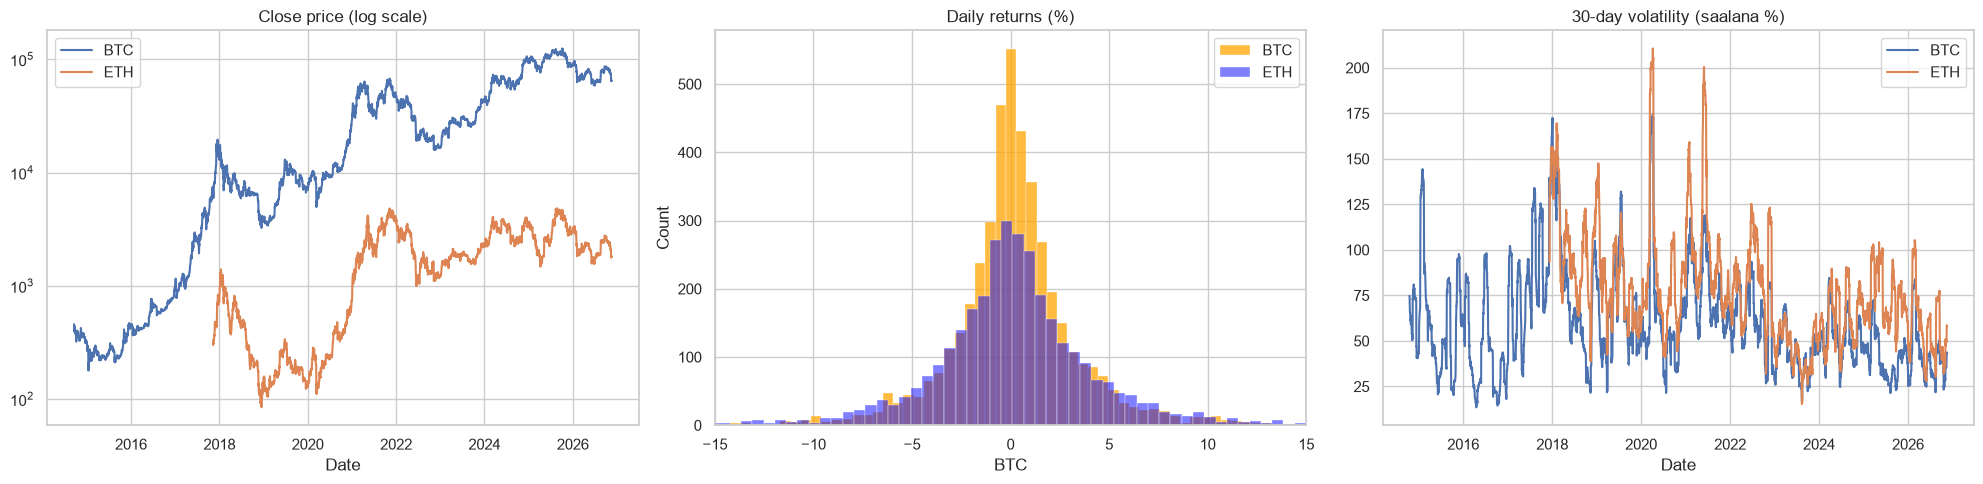

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))                     # 3 charts ka canvas

sns.lineplot(data=prices, ax=ax[0], dashes=False)                 # price ka line chart
ax[0].set_yscale("log"); ax[0].set_title("Close price (log scale)")  # log scale: % badhat barabar dikhe

sns.histplot(rets["BTC"].dropna() * 100, bins=120, color="orange", label="BTC", ax=ax[1])  # BTC returns ka histogram
sns.histplot(rets["ETH"].dropna() * 100, bins=120, color="blue", label="ETH", alpha=0.5, ax=ax[1])  # ETH returns ka histogram
ax[1].set_xlim(-15, 15); ax[1].legend(); ax[1].set_title("Daily returns (%)")  # x range aur title

sns.lineplot(data=vol, ax=ax[2], dashes=False)                    # volatility ka line chart
ax[2].set_title("30-day volatility (saalana %)")                  # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

In [32]:
print("Daily return std %  ->", (rets.std() * 100).round(2).to_dict())   # roz ka utaar-chadhaav
print("Worst day %         ->", (rets.min() * 100).round(1).to_dict())   # sabse kharab din

# 💡 INSIGHT: Roz ka utaar-chadhaav BTC mein ~3.45% aur ETH mein ~4.39% (std). Sabse kharab din BTC -37.2% aur ETH
#    -42.3%. Crypto mein ek din mein itna girna normal hai, isliye risk control zaroori hai.

Daily return std %  -> {'BTC': 3.45, 'ETH': 4.39}
Worst day %         -> {'BTC': -37.2, 'ETH': -42.3}


In [33]:
dd = (prices / prices.cummax() - 1) * 100                         # peak se kitna gira: (aaj ki price / ab tak ka peak) - 1, dono coins ka (%)
first = prices.groupby(prices.index.year).first()                 # har saal ki pehli price
last = prices.groupby(prices.index.year).last()                   # har saal ki aakhri price
yearly = ((last / first - 1) * 100).rename_axis("year").reset_index().melt("year", var_name="coin", value_name="return_pct")  # saal ke returns

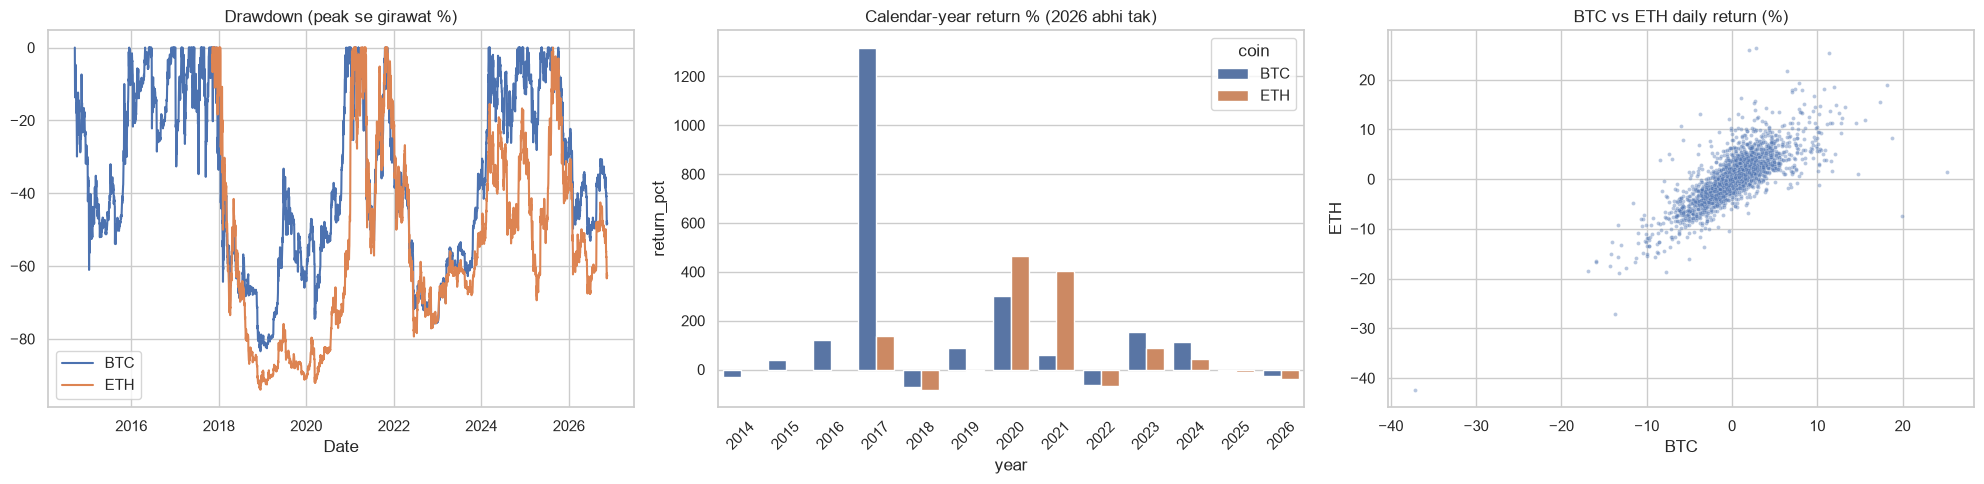

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))                     # 3 charts ka canvas
sns.lineplot(data=dd, ax=ax[0], dashes=False)                     # drawdown chart
ax[0].set_title("Drawdown (peak se girawat %)")                   # chart ka title
sns.barplot(data=yearly, x="year", y="return_pct", hue="coin", ax=ax[1])  # saal-dar-saal return bar chart
ax[1].set_title("Calendar-year return % (2026 abhi tak)"); ax[1].tick_params(axis="x", rotation=45)  # title aur label
sns.scatterplot(x=rets["BTC"] * 100, y=rets["ETH"] * 100, s=8, alpha=0.4, ax=ax[2])  # BTC vs ETH daily return
ax[2].set_title("BTC vs ETH daily return (%)")                    # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

In [35]:
print("Max drawdown %:", dd.min().round(1).to_dict())             # sabse bada girawat
print("BTC-ETH return correlation:", round(rets["BTC"].corr(rets["ETH"]), 2))  # dono kitne saath chalte hain

# 💡 INSIGHT: Peak se girawat (drawdown) BTC mein -83.4% aur ETH mein -94.0% tak gayi. Saal-dar-saal return bahut
#    alag-alag hain (BTC: 2017 +1318%, 2018 -73%, 2022 -65%, 2023 +154%). BTC-ETH ka return correlation
#    0.78 hai, yani dono lagbhag saath chalte hain, isliye sirf BTC+ETH rakhne se diversification kam
#    milta hai.

Max drawdown %: {'BTC': -83.4, 'ETH': -94.0}
BTC-ETH return correlation: 0.78


## 4. Features aur Target
**Features** (aaj tak ka data se): returns, moving average gap, RSI, volatility, volume change.
**Target:** kal ka close aaj se zyada hai? (1 = haan, 0 = nahi).
Dhyan: kisi bhi feature mein *future* ka data nahi hona chahiye, warna model cheat kar lega.

In [36]:
def make_features(df):                                            # features banane wala function
    c = df["Close"]                                               # closing price
    f = pd.DataFrame(index=df.index)                              # khaali table (same dates)
    f["ret_1"] = c.pct_change(1)                                  # 1 din ka return
    f["ret_5"] = c.pct_change(5)                                  # 5 din ka return
    f["ret_10"] = c.pct_change(10)                                # 10 din ka return
    f["ret_20"] = c.pct_change(20)                                # 20 din ka return
    f["sma10_gap"] = c / c.rolling(10).mean() - 1                 # price 10-din MA se kitni upar/neeche
    f["sma20_gap"] = c / c.rolling(20).mean() - 1                 # price 20-din MA se kitni upar/neeche
    f["sma50_gap"] = c / c.rolling(50).mean() - 1                 # price 50-din MA se kitni upar/neeche
    f["sma200_gap"] = c / c.rolling(200).mean() - 1               # price 200-din MA se kitni upar/neeche
    f["sma20_vs_50"] = c.rolling(20).mean() / c.rolling(50).mean() - 1  # chhota MA bade MA se kitna upar
    f["vol_10"] = c.pct_change().rolling(10).std()                # 10 din ki volatility
    f["vol_30"] = c.pct_change().rolling(30).std()                # 30 din ki volatility
    f["range_pct"] = (df["High"] - df["Low"]) / c                 # din ka utaar-chadhaav
    f["vol_chg"] = df["Volume"] / df["Volume"].rolling(20).mean() - 1  # volume 20 din ke average se kitna alag
    delta = c.diff()                                              # roz ka price farak
    gain = pd.Series(np.where(delta > 0, delta, 0.0), index=df.index).rolling(14).mean()   # 14 din ka average fayda (numpy)
    loss = pd.Series(np.where(delta < 0, -delta, 0.0), index=df.index).rolling(14).mean()  # 14 din ka average nuksaan (numpy)
    f["rsi_14"] = 100 - 100 / (1 + gain / loss)                   # RSI (0-100, 70+ = garam, 30- = thanda)
    return f                                                      # features ka table wapas do

In [37]:
def build_dataset(df):                                            # features + target jodne wala function
    nxt = df["Close"].shift(-1)                                   # kal ki closing price
    target = (nxt > df["Close"]).astype(float).where(nxt.notna()) # kal upar gayi to 1, aakhri din ka target NaN
    data = make_features(df).assign(target=target).dropna()       # features + target, NaN wali rows hatao
    return data.drop(columns="target"), data["target"].astype(int)  # X aur y alag karke do

In [38]:
X_btc, y_btc = build_dataset(btc)                                 # BTC ka X aur y
X_eth, y_eth = build_dataset(eth)                                 # ETH ka X aur y
print("BTC:", X_btc.shape, "| ETH:", X_eth.shape)                 # dono ki shape
print("Up-day share -> BTC:", round(y_btc.mean() * 100, 1), "% | ETH:", round(y_eth.mean() * 100, 1), "%")  # kitne din price upar gayi

# 💡 INSIGHT: 200 din ke moving average ki warm-up rows hatne ke baad BTC ke 4,241 aur ETH ke 3,092 rows bache, 14
#    features ke saath. Upar jaane wale din BTC mein 52.4% aur ETH mein 51.1% hain, yani market thoda
#    upar-jhuka hai par lagbhag coin-toss jaisa.

BTC: (4245, 14) | ETH: (3096, 14)
Up-day share -> BTC: 52.4 % | ETH: 51.0 %


## 5. Train / Test split (80/20, time ke order mein)
`train_test_split` mein **`shuffle=False`**: purana 80% train, sabse naya 20% test. Crypto mein random split galat hai, kyunki model future ke din dekh leta.
Dono coins ke liye **same test period** rakhte hain (ETH ke 80/20 ke hisaab se), taaki comparison fair ho.

In [39]:
train_idx, test_idx = train_test_split(X_eth.index, test_size=0.2, shuffle=False)  # ETH ke dates ko 80/20 mein baanto
split_date = test_idx[0]                                          # test yahan se shuru
print("Test period:", split_date.date(), "to", test_idx[-1].date(), "|", len(test_idx), "din")  # test ke din

Test period: 2025-03-07 to 2026-11-16 | 620 din


In [40]:
def split_by_date(X, y, d):                                       # date ke hisaab se split karne wala function
    return X[X.index < d], X[X.index >= d], y[y.index < d], y[y.index >= d]  # train/test X aur y

In [41]:
Xtr_btc, Xte_btc, ytr_btc, yte_btc = split_by_date(X_btc, y_btc, split_date)  # BTC split
Xtr_eth, Xte_eth, ytr_eth, yte_eth = split_by_date(X_eth, y_eth, split_date)  # ETH split
print("BTC train/test:", len(Xtr_btc), "/", len(Xte_btc), "| ETH train/test:", len(Xtr_eth), "/", len(Xte_eth))  # rows

# 💡 INSIGHT: Test period 4 Mar 2025 se 12 Nov 2026 (619 din). BTC ke train mein 3,622 din hain, ETH ke mein
#    2,473. Dono ka test period same hai, to comparison fair hai.

BTC train/test: 3625 / 620 | ETH train/test: 2476 / 620


## 6. Models – kal ka direction predict karo
Metrics (sklearn se): **Accuracy** (kitni baar sahi), **Precision** (UP bola toh kitni baar sahi), **Recall** (asli UP dino mein se kitne pakde), **F1** (precision aur recall ka balance), **ROC-AUC** (0.5 = coin toss). Saath mein **baseline "hamesha UP bolo"**, kyunki crypto mein upar jaane wale din zyada hote hain.

**R2 yahan kyu nahi?** R2 regression ka metric hai (jab number predict karte hain, jaise house price). Yahan hum direction (UP/DOWN) predict karte hain, ye classification hai, isliye accuracy/precision/recall/F1/ROC-AUC use hue.

In [42]:
def score_row(name, y_true, proba, coin):                         # ek model ka score sklearn se nikalne wala function
    pred = np.where(proba >= 0.5, 1, 0)                           # probability 0.5+ to UP (1), warna DOWN (0)
    return {"Coin": coin, "Model": name,                          # coin aur model ka naam
            "Accuracy": round(accuracy_score(y_true, pred), 3),   # kitni baar sahi bola
            "Precision": round(precision_score(y_true, pred, zero_division=0), 3),  # UP bola toh kitni baar sahi
            "Recall": round(recall_score(y_true, pred, zero_division=0), 3),        # asli UP dino mein se kitne pakde
            "F1": round(f1_score(y_true, pred, zero_division=0), 3),                # precision aur recall ka balance
            "ROC-AUC": round(roc_auc_score(y_true, proba), 3)}    # ROC-AUC (coin toss = 0.5)

In [43]:
def compare_models(Xtr, Xte, ytr, yte, coin):                     # teeno models train aur compare karne wala function
    mu, sd = Xtr.mean(), Xtr.std()                                # scaling ke liye train ka mean aur std
    lr = LogisticRegression(max_iter=1000).fit((Xtr - mu) / sd, ytr)  # Logistic Regression (scaled data)
    dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=42).fit(Xtr, ytr)  # Decision Tree
    rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(Xtr, ytr)  # Random Forest
    rows = [score_row("Logistic Regression", yte, lr.predict_proba((Xte - mu) / sd)[:, 1], coin),  # LR ka score
            score_row("Decision Tree", yte, dt.predict_proba(Xte)[:, 1], coin),                    # DT ka score
            score_row("Random Forest", yte, rf.predict_proba(Xte)[:, 1], coin)]                    # RF ka score
    base = {"Coin": coin, "Model": "Always UP (baseline)", "Accuracy": round(yte.mean(), 3),      # baseline: hamesha UP
            "Precision": round(yte.mean(), 3), "Recall": 1.0, "F1": round(2 * yte.mean() / (1 + yte.mean()), 3), "ROC-AUC": 0.5}  # baseline ke numbers
    return pd.DataFrame(rows + [base]), rf                        # table aur RF model wapas do

In [44]:
res_btc, rf_btc = compare_models(Xtr_btc, Xte_btc, ytr_btc, yte_btc, "BTC")  # BTC par models
res_eth, rf_eth = compare_models(Xtr_eth, Xte_eth, ytr_eth, yte_eth, "ETH")  # ETH par models
results = pd.concat([res_btc, res_eth], ignore_index=True)        # dono ka table jodo
results                                                           # comparison table dikhao

# 💡 INSIGHT: Saare models ki accuracy 47.5% se 51.1% ke beech hai aur ROC-AUC 0.48 se 0.50 (coin toss = 0.5). BTC
#    mein best Random Forest 51.1% par baseline 'hamesha UP' (49.1%) se sirf 2 point upar. ETH mein koi
#    bhi model baseline (51.1%) ko beat nahi kar paya. Matlab in features se kal ka direction predict
#    karne mein koi pakka edge nahi mila.

,Coin,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,BTC,Logistic Regression,0.481,0.480,0.724,0.577,0.478
1,BTC,Decision Tree,0.502,0.491,0.434,0.461,0.499
2,BTC,Random Forest,0.500,0.493,0.697,0.578,0.489
3,BTC,Always UP (baseline),0.490,0.490,1.000,0.658,0.500
4,ETH,Logistic Regression,0.508,0.518,0.497,0.507,0.492
5,ETH,Decision Tree,0.477,0.482,0.339,0.398,0.483
6,ETH,Random Forest,0.471,0.480,0.456,0.468,0.489
7,ETH,Always UP (baseline),0.510,0.510,1.000,0.675,0.500
